# GATE (Deep Image Prior)

This tutorial demonstrates how to use the Deep Image Prior Reconstruction algorithm (`DIPRecon`) to reconstruction PET data using the MRI image as the prior image. In this case, we'll use listmode time-of-flight reconstruciton.

* This notebook requires `monai` to be installed

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/GATE-mMR-BrainInWater", extras=["mri"])  # with the MRI, the network's input
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/GATE-mMR-BrainInWater")

PET/GATE-mMR-BrainInWater: already downloaded


In [2]:
import torch
import torch.nn as nn
from torch.optim import LBFGS
import pytomography
from pytomography.metadata import ObjectMeta
from pytomography.metadata.PET import PETLMProjMeta, PETTOFMeta
from pytomography.projectors.PET import PETLMSystemMatrix
from pytomography.algorithms import OSEM, DIPRecon
from pytomography import io
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.transforms.shared import GaussianFilter
from pytomography.utils import sss
import matplotlib.pyplot as plt
import gc
import numpy as np
from monai.transforms import ScaleIntensityd, CropForeground, Compose, DivisiblePadd, SpatialCropd, ThresholdIntensityd

## How much memory this needs

The 107 million list-mode events are kept on the GPU, and fitting the network takes most of the rest: with the network these docs use (`START_CHANNELS = 12`), the tutorial peaks at about 8.0 GB of GPU memory, more than an 8 GB GPU has. The cell below sets the network's size, and its comments give the GPU memory each size takes: `START_CHANNELS = 8` fits an 8 GB GPU. On Windows, GPU memory counts as RAM too, so the memory budget below leaves room for the network (`NETWORK_GB`): the scatter estimate (a 34.6 GB TOF sinogram if held whole) is computed one group of angles at a time, within what is left. The OSEM reconstruction and the scatter estimate print their estimates before they run (`estimate_memory`); the network's `NETWORK_GB` come on top. The tutorial peaks at about 22 GB of RAM (measured on Windows), and needs about that whatever `RAM_GB` is, so it does not fit in 16 GB: the events and their randoms, scatter and sensitivity are held whole, which the budget does not split yet.

In [3]:
RAM_GB = 25 # memory (RAM) this tutorial may use, in GB; it needs about 22 GB however low this is

# The Deep Image Prior's network: a UNet (defined below) whose 5 levels are 1, 2, 4, 8 and 16 times START_CHANNELS
# wide. Fitting it takes most of the GPU memory this tutorial needs; the list-mode events, their additive term and
# the images keep about 2.5 GB more on the GPU for the whole run. GPU memory in GB, as
# torch.cuda.max_memory_allocated counts it, with PyTomography 4.0.0rc1 and PyTorch 2.14:
#
#   START_CHANNELS   fitting the network   the tutorial's peak
#   12               5.5                   8.0   more than an 8 GB GPU has; the images on this page
#   10               4.7                   7.2
#    8               3.7                   6.2   fits an 8 GB GPU
#    6               2.9                   5.4
#
# PyTorch keeps freed blocks for reuse, so the GPU needs some room above these.
START_CHANNELS = 8
LBFGS_HISTORY = 10 # past steps L-BFGS keeps, 2 copies of the network's parameters each: 0.24 GB at 12 channels
NETWORK_GB = 7 * START_CHANNELS / 12 # what fitting the network takes, in GB, which on Windows counts as RAM too
pytomography.set_memory_budget(RAM_GB - NETWORK_GB) # what the scatter estimate and the reconstructions may use

The Deep Image Prior requires an initial reconstructed image using a standard reconstruction algorithm like OSEM. The code below is a summary of everything in the GATE listmode-TOF tutorial: `io.PET.read_gate` reads the simulation (and places it on the phantom's MR, from the dataset registry), and keeps what it reads in `OUTPUT`, so later runs, and the other GATE tutorials, load it from there. The grid is finer here: 1.25 mm voxels, centred where `read_gate` placed the scanner.

In [4]:
LOAD_FROM_ROOT = False # True: read the ROOT files again instead of the results cached in OUTPUT

path = DATA / 'PET' / 'GATE-mMR-BrainInWater'
macro = path / 'mMR_Geometry.mac'  # the scanner, as the simulation's GATE macro describes it
paths = [path / 'simple_phantom' / f'mMR_voxBrain_withSimplePhantom_{i}.root' for i in range(1, 55)]  # its 54 runs


def read_gate(events, tof_meta=None, normalization=None):
    """io.PET.read_gate for one kind of coincidence: (events, object_meta, proj_meta). Reading the 54 ROOT files takes
    a few minutes, so the first run keeps the result in OUTPUT and later runs load it from there."""
    name = f'gate_{events}' + ('' if tof_meta is None else f'_tof{tof_meta.num_bins}') + ('' if normalization is None else '_norm')
    cache = OUTPUT / f'{name}.pt'
    if LOAD_FROM_ROOT or not cache.exists():
        # doi: the lines of response end 9 mm inside the crystals, the mean depth of interaction
        torch.save(io.PET.read_gate(paths, macro, events=events, tof_meta=tof_meta, normalization=normalization,
                                    doi=9), cache)
    return torch.load(cache, weights_only=False)


speed_of_light = 0.3 #mm/ps
fwhm_tof_resolution = 550 * speed_of_light / 2 #ps to position along LOR
TOF_range = 1000 * speed_of_light #ps to position along LOR (full range)
num_tof_bins = 21
tof_meta = PETTOFMeta(num_tof_bins, TOF_range, fwhm_tof_resolution, n_sigmas=3)

# Every coincidence in its TOF bin, with the normalization weights of every crystal pair (read_gate sets those without
# calibration data to 0), and the delayed coincidences
detector_ids, object_meta, proj_meta = read_gate('prompts', tof_meta=tof_meta,
                                                 normalization=path / 'normalization_weights.npy')
detector_ids_delays, _, _ = read_gate('delayeds')
info = proj_meta.info

sinogram_randoms_estimate = io.PET.listmode_to_sinogram(
    detector_ids_delays,
    info
)
del detector_ids_delays # binned: the events are not needed again
sinogram_randoms_estimate = io.PET.smooth_randoms_sinogram(
    sinogram_randoms_estimate,
    info,
    fwhm_r=20,
    fwhm_theta=7,
    fwhm_z=40
)
sinogram_randoms_estimate = io.PET.randoms_sinogram_to_sinogramTOF(
    sinogram_randoms_estimate,
    tof_meta = tof_meta,
    coincidence_timing_width = 4300
) # coinicidence timing window for this GATE simulation was set to 4300ps
lm_randoms_estimate = io.PET.sinogram_to_listmode(
    detector_ids,
    sinogram_randoms_estimate,
    info,
)

# The grid: 1.25 mm voxels, centred where read_gate placed the scanner in the patient
object_meta = object_meta.with_grid(dr=(1.25, 1.25, 1.25), shape=(204, 204, 154))  # mm, voxels
# The phantom's attenuation map (1/cm, in GATE's world), placed in the patient and put on the grid, in 1/mm
atten_map = io.attenuation_map(io.PET.gate_image(path / 'umap_mMR_brainSimplePhantom.hv', proj_meta, units='1/cm'),
                               object_meta)
# read_gate's proj_meta holds the events, the scanner's info, the TOF bins and the normalization weights
psf_transform = GaussianFilter(4)
system_matrix = PETLMSystemMatrix(
       object_meta,
       proj_meta,
       obj2obj_transforms = [psf_transform],
       N_splits=10,
       attenuation_map=atten_map,
)
lm_norm = system_matrix._compute_sensitivity_projection(all_ids=False)
additive_term = lm_randoms_estimate / lm_norm
additive_term[additive_term.isnan()] = 0 # remove NaN values
# Provide the random-only
likelihood = PoissonLogLikelihood(
        system_matrix,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
recon_without_scatter_estimation = recon_algorithm(50,1)

# Scatter correction (its peak RAM and GPU memory first, before it runs)
print(sss.estimate_sss_memory(object_meta, proj_meta, system_matrix, sinogram_random=sinogram_randoms_estimate,
                              tof_meta=tof_meta, sinogram_interring_stepsize=6, sinogram_intraring_stepsize=6,
                              num_dense_tof_bins=25))
scatter_sinogram = sss.get_sss_scatter_estimate(
        object_meta,
        proj_meta,
        recon_without_scatter_estimation,
        atten_map,
        system_matrix,
        sinogram_random=sinogram_randoms_estimate,
        tof_meta=tof_meta,
        num_dense_tof_bins=25,
        image_stepsize=6,
        sinogram_interring_stepsize=6,
        sinogram_intraring_stepsize=6,
        N_splits=1)
lm_scatter_estimate = io.PET.sinogram_to_listmode(proj_meta.detector_ids, scatter_sinogram, proj_meta.info)
# Save memory, these are not needed anymore
del(system_matrix)
del(likelihood)
del(scatter_sinogram)
del(sinogram_randoms_estimate)
gc.collect()

# System matrix with no PSF modeling
system_matrix = PETLMSystemMatrix(
       object_meta,
       proj_meta,
       obj2obj_transforms = [],
       N_splits=10,
       attenuation_map=atten_map,
)
additive_term = (lm_scatter_estimate + lm_randoms_estimate) / lm_norm
additive_term[additive_term.isnan()] = 0
likelihood = PoissonLogLikelihood(
        system_matrix,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=1)) # its peak RAM and GPU memory, before it runs
recon_lm_tof = recon_algorithm(50,1)
# The events' host copy (the system matrix keeps them on the GPU), the per-event estimates (in additive_term now) and
# the normalization weights (used for the sensitivity image, computed above) are not needed again: freeing them
# leaves room for the network
del detector_ids, lm_randoms_estimate, lm_scatter_estimate, lm_norm
proj_meta.weights_sensitivity = None
gc.collect()

Single scatter simulation (TOF, lazy, N_splits 1)
Peak ~ 24.4 GB RAM, 5.2 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 5.4 GB RAM, 0.1 GB GPU (PET image and attenuation map 0.1 GPU, randoms 1.6 RAM, events binned lazily 0.9 RAM, sensitivity sinogram of the sinogram system matrix 1.6 RAM, interpolated estimate (lazy: angle and radius of the sampled ring pairs, host) 1.2 RAM)
  projector chunks: 3.4 GB RAM, 3.3 GB GPU (largest step on the host: scaling (93 subsets) 3.4 RAM, sparse estimate (GPU) 0.4 GPU, interpolation over angle and radius (GPU) 0.6 GPU, scaling (93 subsets) (GPU) 2.4 GPU)
  Python, CUDA, allocator: 10.3 GB RAM, 1.9 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.2 GPU, memory the allocators keep (Windows) 7.3 RAM)
(plus whatever else your script keeps)


OSEM (PETLMSystemMatrix): 1 subset, memory budget 20.3333 GB
Peak ~ 22.1 GB RAM, 11.6 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.6 GB RAM, 2.3 GB GPU (events and their projector order 1.7 GPU, sensitivity weights 1.6 RAM, sensitivity and normalisation images (1) 0.1 GPU, image, update and attenuation map 0.1 GPU, projections (the data) 0.00 GPU, additive term 0.4 GPU)
  one subset at a time: 0.00 GB RAM, 5.1 GB GPU (expected counts, ratio and temporaries (one subset) 1.7 GPU, positions of the subset's events 0.9 GPU, building a subset's projector order (its first projection) 2.5 GPU)
  projector chunks: 0.00 GB RAM, 0.7 GB GPU (projector chunk 0.7 GPU)
  Python, CUDA, allocator: 8.9 GB RAM, 3.5 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 2.9 GPU, memory the allocators keep (Windows) 5.8 RAM)
To use less: 2 subsets ~ 17.7 GB RAM, 8.5 GB GPU, N_s

0

In [5]:
filter = GaussianFilter(3)
filter.configure(object_meta, proj_meta)
recon_lm_tof_filtered = filter(recon_lm_tof)

The Deep Image Prior requires a neural network architecture that takes as input a 3D image (the prior image, in this case the MRI) and outputs a 3D image (the PET image). In this case, we'll define a simple UNet architecture (similar to the one in the DIPRecon paper) below:

* The UNet has 5 layers and reduces the object dimensions by a factor of 2 (but increases the number of channels) in each downward block.

In [6]:
def get_downward_block(in_channels, out_channels):
    return nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(out_channels),
            nn.LeakyReLU(),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(out_channels),
            nn.LeakyReLU(), 
        ) 
    
def get_downsample_block(out_channels):
    return nn.Sequential(
            nn.Conv3d(out_channels, out_channels, kernel_size=3, stride=2, padding=(1,1,1)),
            nn.BatchNorm3d(out_channels),
            nn.LeakyReLU(),
        ) 
    
def get_bottleneck_block(in_channels, out_channels):
    return nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(out_channels),
            nn.LeakyReLU(),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(out_channels),
            nn.LeakyReLU(),
        ) 
    
def get_bilinear_upsample_block(in_channels, out_channels):
    return nn.Sequential(
            nn.Upsample(scale_factor=2, mode='trilinear', align_corners=True),
            nn.Conv3d(in_channels, out_channels, kernel_size=1, padding='same'),
        )
    
def get_upward_block(in_channels):
    return nn.Sequential(
            nn.Conv3d(in_channels, in_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(in_channels),
            nn.LeakyReLU(),
            nn.Conv3d(in_channels, in_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(in_channels),
            nn.LeakyReLU(),
        )
    
def get_final_block(in_channels):
    return nn.Sequential(
            nn.Conv3d(in_channels, in_channels, kernel_size=3, padding='same'),
            nn.BatchNorm3d(in_channels),
            nn.LeakyReLU(),
            nn.Conv3d(in_channels, 1, kernel_size=3, padding='same'),
        )
    
class UNetCustom(nn.Module):
    def __init__(self, n_channels=[4, 8, 16, 32, 64]):
        super().__init__()       
        self.downward_block1 = get_downward_block(1, n_channels[0])
        self.downward_block2 = get_downward_block(n_channels[0], n_channels[1])
        self.downward_block3 = get_downward_block(n_channels[1], n_channels[2])
        self.downward_block4 = get_downward_block(n_channels[2], n_channels[3])
        self.downsample_block1 = get_downsample_block(n_channels[0])
        self.downsample_block2 = get_downsample_block(n_channels[1])
        self.downsample_block3 = get_downsample_block(n_channels[2])
        self.downsample_block4 = get_downsample_block(n_channels[3])
        self.bottleneck_block = get_bottleneck_block(n_channels[3], n_channels[4])
        self.upsample_block1 = get_bilinear_upsample_block(n_channels[4], n_channels[3])
        self.upsample_block2 = get_bilinear_upsample_block(n_channels[3], n_channels[2])
        self.upsample_block3 = get_bilinear_upsample_block(n_channels[2], n_channels[1])
        self.upsample_block4 = get_bilinear_upsample_block(n_channels[1], n_channels[0])
        self.upward_block1 = get_upward_block(n_channels[3])
        self.upward_block2 = get_upward_block(n_channels[2])
        self.upward_block3 = get_upward_block(n_channels[1])
        self.final_block = get_final_block(n_channels[0])
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1 = self.downward_block1(x)
        x = self.downsample_block1(x1)
        x2 = self.downward_block2(x)
        x = self.downsample_block2(x2)
        x3 = self.downward_block3(x)
        x = self.downsample_block3(x3)
        x4 = self.downward_block4(x)
        x = self.downsample_block4(x4)
        x = self.bottleneck_block(x)
        x = self.upsample_block1(x) + x4
        x = self.upward_block1(x)
        x = self.upsample_block2(x) + x3
        x = self.upward_block2(x)
        x = self.upsample_block3(x) + x2
        x = self.upward_block3(x)
        x = self.upsample_block4(x) + x1
        x = self.final_block(x)
        return x

Note that this network actually expects a 5D image of shape `[batch_size, n_channels, Lx, Ly, Lz]`, so we need to take this into account.

In [7]:
test_input = torch.ones((1,1,128,128,128))
test_output = UNetCustom()(test_input)
print(test_input.shape)
print(test_output.shape)

torch.Size([1, 1, 128, 128, 128])
torch.Size([1, 1, 128, 128, 128])


The next thing the DIP Prior needs is a class that implements a `fit` and `predict` method. The `fit` method should take in an object (the PET image in this case) and update the neural networks weights. The `predict` method should yield the current prediction of the neural network. In PyTomography, this is left very general and up to the user to allow for more flexibility in experimentation (feel free to grab this code though).

In [8]:
class DIPPrior():
    def __init__(
        self,
        network,
        anatomical_image,
        pipeline, # pipeline for preprocessing MRI image
        scale_factor=1, # constant to scale MRI image by
        n_epochs=10, # how many epochs the network trains for when fitting
        lr = 0.1, # learning rate when fitting
        history_size = 10, # L-BFGS: past steps kept, 2 copies of the network's parameters each
    ):
        self.network = network
        self.anatomical_image = anatomical_image
        self.pipeline = pipeline
        self.n_epochs = n_epochs
        self.scale_factor = scale_factor
        self.lr = lr
        self.history_size = history_size
        self.max_iter = 20 # L-BFGS iterations per epoch
        self.line_search_fn = None # L-BFGS line search: None (fixed step lr) or 'strong_wolfe'
        
    def fit(self, object):
        # This method trains the network for n_epochs at a learning rate of lr
        data = self.pipeline({'NM': object.unsqueeze(0), 'MR': self.anatomical_image.unsqueeze(0)})
        # history_size: 10 as in the paper (100 kept 200 copies of the network's parameters on the GPU)
        optimizer_lfbgs = LBFGS(self.network.parameters(), lr=self.lr, max_iter=self.max_iter, history_size=self.history_size, line_search_fn=self.line_search_fn)
        NM_truth = data['NM'].unsqueeze(0) * self.scale_factor
        network_input = data['MR'].unsqueeze(0)
        criterion = torch.nn.MSELoss()
        def closure(optimizer):
            optimizer.zero_grad()
            NM_prediction = self.network(network_input)
            loss = criterion(NM_prediction, NM_truth)
            loss.backward()
            return loss
        for epoch in range(self.n_epochs):  
            loss = optimizer_lfbgs.step(lambda: closure(optimizer_lfbgs))
        self.network.zero_grad(set_to_none=True)
        with torch.no_grad():
            # Add batch/channel dimension
            network_prediction = self.network(data['MR'].unsqueeze(0)).squeeze()
        self.prior_object = self.pipeline.inverse({'NM': network_prediction.unsqueeze(0)})['NM'].as_tensor().squeeze() / self.scale_factor
        
    def predict(self):        
        return self.prior_object.detach()

In [9]:
# The phantom's MR (NIfTI, 0.4 mm voxels) on the PET grid: load_image reads it with its own place in the patient, and
# .on() averages it over each 1.25 mm voxel
mri_aligned = io.load_image(path / 'fdg_pet_phantom_mri.nii.gz').on(object_meta)

The pipeline for preprocessing the MRI/PET image in the neural network is defined below. Understanding this code requires familiarity with MONAI

In [10]:

mri_crop_above = 250
mri_crop_below = 120

roi_start, roi_end = CropForeground().compute_bounding_box(mri_aligned.unsqueeze(0))
pipeline = Compose([
    SpatialCropd(['MR', 'NM'], roi_start=roi_start, roi_end=roi_end, allow_missing_keys=True),
    DivisiblePadd(['MR', 'NM'], 16, allow_missing_keys=True),
    ThresholdIntensityd(['MR'], mri_crop_above, above=False, cval=mri_crop_above),
    ThresholdIntensityd(['MR'], mri_crop_below, above=True, cval=mri_crop_below),
    ScaleIntensityd(['MR'], 0, 1)
])

Now lets create our DIP prior using our initialized network and pipeline:

In [11]:
torch.manual_seed(0) # the network's starting weights: the same network, and the same images, on every run
net = UNetCustom([START_CHANNELS, 2*START_CHANNELS, 4*START_CHANNELS, 8*START_CHANNELS, 16*START_CHANNELS]).to(pytomography.device)

In [12]:
dip_prior = DIPPrior(
    net,
    mri_aligned,
    pipeline,
    n_epochs= 100,
    scale_factor= 50,
    lr=0.01,
    history_size=LBFGS_HISTORY,
    )

Before we use the DIPRecon reconstruction algorithm, we first need to pretrain our network on the initial reconstructed PET image

In [13]:
dip_prior.fit(recon_lm_tof)
# the pretrained network's image, the starting point shown on the contrast-noise plot at the end
pretrained_prediction = dip_prior.prior_object.clone()

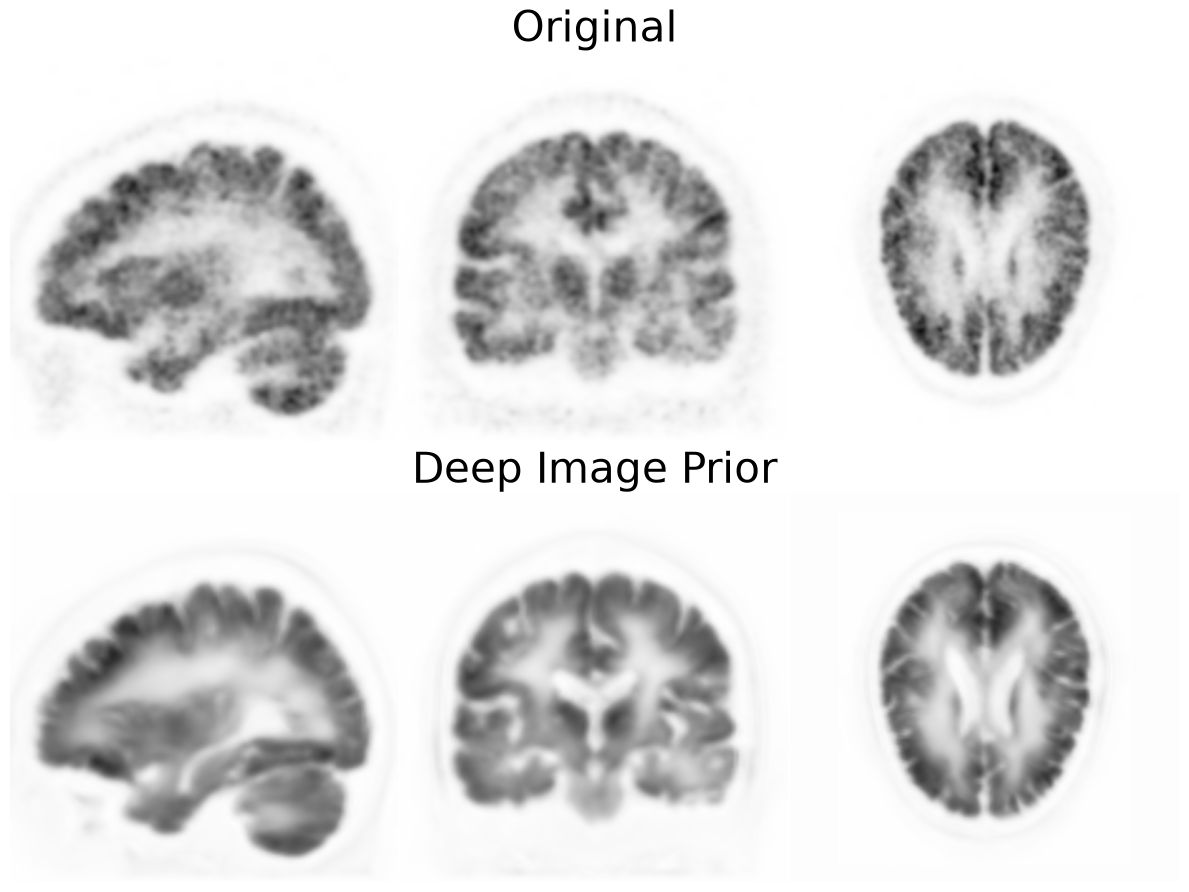

In [14]:
vmax = 0.45
cmap='Greys'
fig, ax = plt.subplots(2,3,figsize=(12,9), gridspec_kw={'wspace': 0})
plt.subplot(231)
plt.imshow(recon_lm_tof_filtered[77,25:-25].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(232)
plt.imshow(recon_lm_tof_filtered[25:-25,103].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.title('Original', fontsize=30)
plt.axis('off')
plt.subplot(233)
plt.imshow(recon_lm_tof_filtered[:,:,77].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(234)
plt.imshow(dip_prior.prior_object[77,25:-25].detach().cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(235)
plt.imshow(dip_prior.prior_object[25:-25,103].detach().cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.title('Deep Image Prior', fontsize=30)
plt.subplot(236)
plt.imshow(dip_prior.prior_object[:,:,77].detach().cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

Now we'll adjust the `DIPPrior` parameters for the reconstruction. As in the paper, each outer iteration refits the network with 10 L-BFGS iterations, with a line search (`strong_wolfe`) that adapts the step size: about 3.5 s per outer iteration here. (This tutorial used to refit with 200 iterations of a fixed step, which took 26 s per outer iteration and gave a smoother image with less contrast.)

In [15]:
dip_prior.n_epochs = 1
dip_prior.max_iter = 10
dip_prior.lr = 1
dip_prior.line_search_fn = 'strong_wolfe'

Finally, we can reconstruct using the `DIPRecon` reconstruction algorithm. The parameter `rho` weighs the regular EM updates against the network (high `rho` means more weight to the network): in each voxel, an update moves about sensitivity / (`rho` x) of an EM step towards the data, where x is the activity, so `rho` depends on the units of the data and the image. This tutorial uses one setting, `rho` = 240, which gave the most contrast for its noise on this data.

To follow the image as it reconstructs, a callback records the contrast between grey and white matter and the noise in white matter after every iteration. The two tissues come with the dataset, in its folder (`gate_braininwater_rois.seg.nrrd`, a 3D Slicer segmentation): the MR's intensity classes, one voxel in from their edges (in this phantom grey matter is the brightest MR class).

In [16]:
from pytomography.callbacks import Callback
# grey and white matter on the grid
brain = io.load_mask(path / 'gate_braininwater_rois.seg.nrrd')
grey = brain.on(object_meta, label='grey_matter', threshold=0.5)
white = brain.on(object_meta, label='white_matter', threshold=0.5)

def contrast_noise(image):
    """Mean grey matter over mean white matter (contrast), and the standard deviation over the mean in white matter (noise)."""
    w = image[white]
    return (image[grey].mean() / w.mean()).item(), (w.std() / w.mean()).item()

class ContrastNoise(Callback):
    """Records the contrast and noise of the image after every iteration."""
    def __init__(self):
        self.contrast, self.noise = [], []
    def run(self, object, n_iter, n_subset=None):
        c, n = contrast_noise(object)
        self.contrast.append(c)
        self.noise.append(n)
        return object

rho = 240
recon_algorithm = DIPRecon(
    likelihood = likelihood,
    prior_network=dip_prior,
    rho=rho,
)

In [17]:
curve_DIP = ContrastNoise()
recon_DIP = recon_algorithm(n_iters=100, subit1=2, callback=curve_DIP)

And we can compare to the original

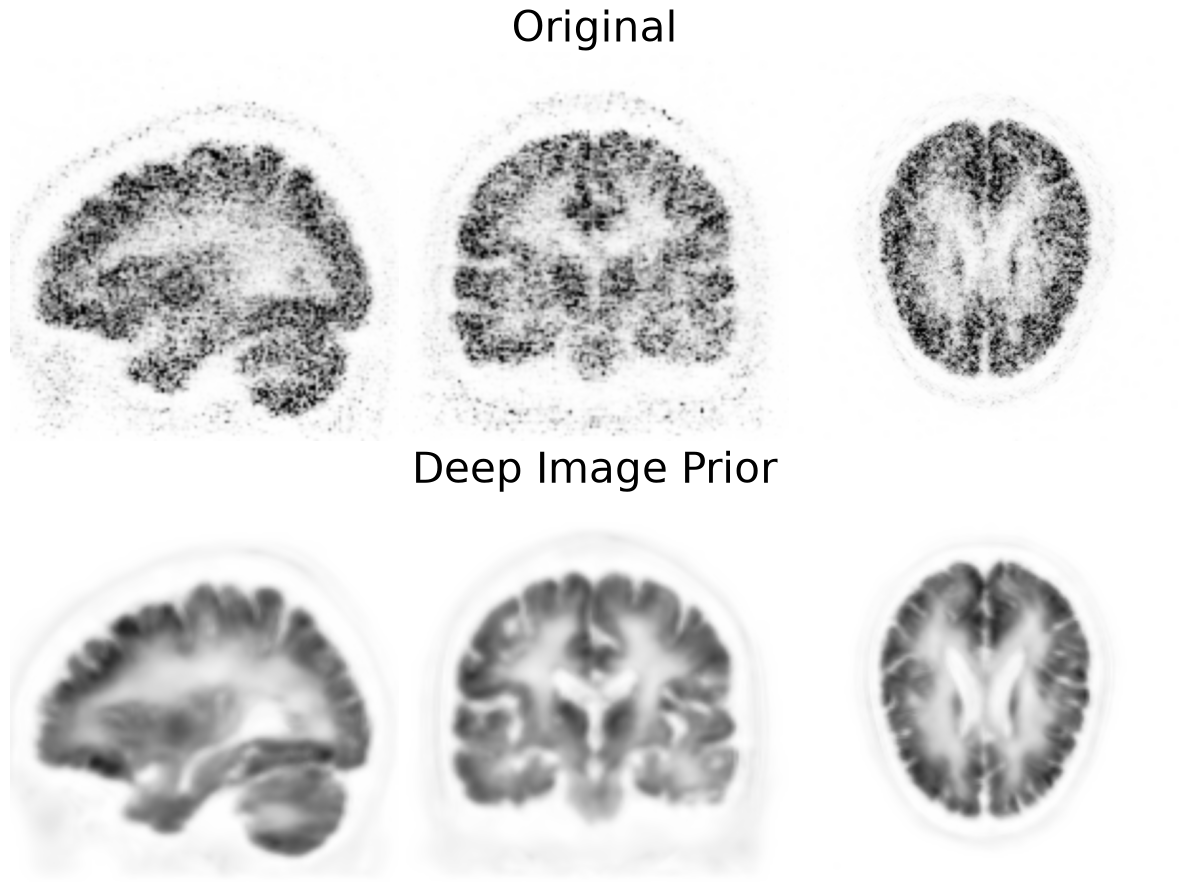

In [18]:
vmax = 0.45
cmap = 'Greys'
fig, ax = plt.subplots(2,3,figsize=(12,9), gridspec_kw={'wspace': 0})
plt.subplot(231)
plt.imshow(recon_lm_tof[77,25:-25].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(232)
plt.imshow(recon_lm_tof[25:-25,103].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.title('Original', fontsize=30)
plt.axis('off')
plt.subplot(233)
plt.imshow(recon_lm_tof[:,:,77].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(234)
plt.imshow(recon_DIP[77,25:-25].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(235)
plt.imshow(recon_DIP[25:-25,103].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.title('Deep Image Prior', fontsize=30)
plt.subplot(236)
plt.imshow(recon_DIP[:,:,77].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

The Deep Image Prior image keeps the grey/white matter contrast of the OSEM image while removing most of its noise. The contrast and noise defined above put numbers on this:

In [19]:
for name, image in (('OSEM', recon_lm_tof), ('OSEM, 3 mm filter', recon_lm_tof_filtered), ('Deep Image Prior', recon_DIP)):
    c, n = contrast_noise(image)
    print(f'{name:18s} contrast {c:.2f}, noise {n:.2f}')

OSEM               contrast 4.03, noise 0.87
OSEM, 3 mm filter  contrast 3.97, noise 0.54
Deep Image Prior   contrast 4.08, noise 0.51


A post-filtered OSEM image only trades noise for contrast. The Deep Image Prior image has less noise than either OSEM image, at about the contrast of the filtered one.

## Contrast against noise

Contrast against noise shows where the Deep Image Prior stands: post-filtered OSEM with Gaussian filters of 0 to 6 mm FWHM, and the Deep Image Prior after every iteration of the reconstruction above.

In [20]:
# post-filtered OSEM
osem_curve = []
for fwhm in (0, 2, 3, 4, 5, 6):
    image = recon_lm_tof
    if fwhm:
        gauss = GaussianFilter(fwhm)
        gauss.configure(object_meta, proj_meta)
        image = gauss(recon_lm_tof)
    osem_curve.append(contrast_noise(image))

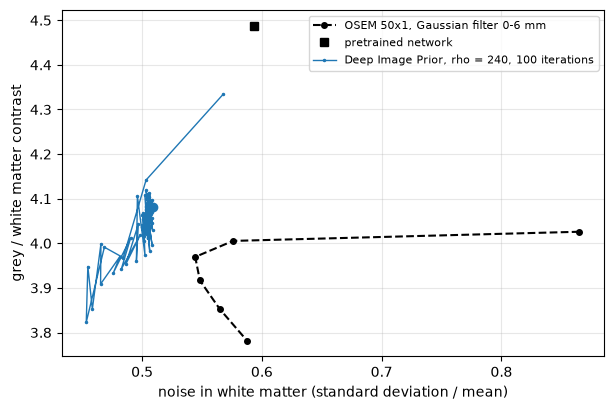

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot([n for c, n in osem_curve], [c for c, n in osem_curve], 'k--o', ms=4, label='OSEM 50x1, Gaussian filter 0-6 mm')
c, n = contrast_noise(pretrained_prediction)
ax.plot(n, c, 'ks', label='pretrained network')
line, = ax.plot(curve_DIP.noise, curve_DIP.contrast, '.-', ms=3, lw=1, label=f'Deep Image Prior, rho = {rho:g}, 100 iterations')
ax.plot(curve_DIP.noise[-1], curve_DIP.contrast[-1], 'o', color=line.get_color(), ms=6)
ax.set_xlabel('noise in white matter (standard deviation / mean)')
ax.set_ylabel('grey / white matter contrast')
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.show()

Every iteration of the Deep Image Prior (one dot per iteration, the last one larger) lies to the left of the post-filtered OSEM curve: less noise than any amount of filtering gives OSEM, and the last iterations at about the contrast of the 3 mm filter. Past 3 mm, filtering costs contrast and even adds noise in white matter, as grey matter spills into it. The curve starts at the pretrained network's image, and the data move the image from it towards less noise. The network's starting weights are seeded (`torch.manual_seed` above), so every run trains the same network from the same start; without the seed, the pretrained image, and with it where the curves start, changes from run to run.

## Save the images

`io.save_dicom` writes the Deep Image Prior image and the OSEM image it started from as DICOM PET series, one file per slice, where `object_meta` places them. GATE data have no patient frame of their own: `read_gate` placed the grid on the phantom's MR, from the dataset registry's record of where the phantom sat in GATE's world, so they line up with that NIfTI file in software that reads both, such as 3D Slicer.

In [22]:
for name, image in [('deep_image_prior', recon_DIP), ('osem', recon_lm_tof)]:
    io.save_dicom(image, OUTPUT / 't_PETGATE_DIP' / name, object_meta, series_description=name, overwrite=True)

In [23]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 6.58, "peak_ram_gb": 19.1}
